# Logistic Regression with Scikit Learn

In [2]:
!pip install opendatasets
import opendatasets as od

In [3]:
dataset_url = "https://www.kaggle.com/jsphyg/weather-dataset-rattle-package"

In [4]:
od.download(dataset_url)


Skipping, found downloaded files in "./weather-dataset-rattle-package" (use force=True to force download)


In [6]:
import os
import pandas  as pd
import numpy as np

In [7]:
data_dir= "./weather-dataset-rattle-package"
os.listdir(data_dir)

['weatherAUS.csv']

In [8]:
train_csv= data_dir + "/weatherAUS.csv"
train_csv

'./weather-dataset-rattle-package/weatherAUS.csv'

In [9]:
raw_df=pd.read_csv(train_csv)

In [10]:
raw_df

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145455,2017-06-21,Uluru,2.8,23.4,0.0,NaN,NaN,E,31.0,SE,...,51.0,24.0,1024.6,1020.3,NaN,NaN,10.1,22.4,No,No
145456,2017-06-22,Uluru,3.6,25.3,0.0,NaN,NaN,NNW,22.0,SE,...,56.0,21.0,1023.5,1019.1,NaN,NaN,10.9,24.5,No,No
145457,2017-06-23,Uluru,5.4,26.9,0.0,NaN,NaN,N,37.0,SE,...,53.0,24.0,1021.0,1016.8,NaN,NaN,12.5,26.1,No,No
145458,2017-06-24,Uluru,7.8,27.0,0.0,NaN,NaN,SE,28.0,SSE,...,51.0,24.0,1019.4,1016.5,3.0,2.0,15.1,26.0,No,No


In [11]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  object 
 1   Location       145460 non-null  object 
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  object 
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  object 
 10  WindDir3pm     141232 non-null  object 
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       89572 non-null

In [12]:
raw_df.dropna(subset=["RainToday","RainTomorrow"],  inplace=True)
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 140787 entries, 0 to 145458
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           140787 non-null  object 
 1   Location       140787 non-null  object 
 2   MinTemp        140319 non-null  float64
 3   MaxTemp        140480 non-null  float64
 4   Rainfall       140787 non-null  float64
 5   Evaporation    81093 non-null   float64
 6   Sunshine       73982 non-null   float64
 7   WindGustDir    131624 non-null  object 
 8   WindGustSpeed  131682 non-null  float64
 9   WindDir9am     131127 non-null  object 
 10  WindDir3pm     137117 non-null  object 
 11  WindSpeed9am   139732 non-null  float64
 12  WindSpeed3pm   138256 non-null  float64
 13  Humidity9am    139270 non-null  float64
 14  Humidity3pm    137286 non-null  float64
 15  Pressure9am    127044 non-null  float64
 16  Pressure3pm    127018 non-null  float64
 17  Cloud9am       88162 non-null   fl

In [13]:
raw_df.describe(include=np.number)

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,140319.000000,140480.00000,140787.000000,81093.000000,73982.000000,131682.000000,139732.000000,138256.000000,139270.000000,137286.000000,127044.000000,127018.000000,88162.000000,84693.000000,140131.000000,138163.000000
mean,12.184824,23.23512,2.349974,5.472516,7.630540,39.970520,13.990496,18.631141,68.826833,51.449288,1017.654577,1015.257963,4.431161,4.499250,16.987066,21.693183
std,6.403879,7.11450,8.465173,4.189132,3.781729,13.578201,8.886210,8.798096,19.063650,20.807310,7.104867,7.035411,2.886594,2.719752,6.496012,6.937784
min,-8.500000,-4.80000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,977.100000,0.000000,0.000000,-7.200000,-5.400000
25%,7.600000,17.90000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,37.000000,1013.000000,1010.400000,1.000000,2.000000,12.300000,16.600000
50%,12.000000,22.60000,0.000000,4.800000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000
75%,16.800000,28.30000,0.800000,7.400000,10.700000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000
max,33.900000,48.10000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.700000


In [14]:
raw_df.describe(include=object)

,Date,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday,RainTomorrow
count,140787,140787,131624,131127,137117,140787,140787
unique,3436,49,16,16,16,2,2
top,2017-06-10,Canberra,W,N,SE,No,No
freq,49,3402,9696,11266,10578,109332,109586


# Exploratory Data Analysis and Visulialization

In [15]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [16]:
sns.set_style("darkgrid")
matplotlib.rcParams["font.size"]=14

matplotlib.rcParams["figure.figsize"]=(10,6)
matplotlib.rcParams["figure.facecolor"]="#00000000"

In [17]:
# select only the numerical column using
numerical_cols=raw_df.select_dtypes(include=[np.number])
numerical_cols

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
0,13.4,22.9,0.6,NaN,NaN,44.0,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8
1,7.4,25.1,0.0,NaN,NaN,44.0,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3
2,12.9,25.7,0.0,NaN,NaN,46.0,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2
3,9.2,28.0,0.0,NaN,NaN,24.0,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5
4,17.5,32.3,1.0,NaN,NaN,41.0,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
145454,3.5,21.8,0.0,NaN,NaN,31.0,15.0,13.0,59.0,27.0,1024.7,1021.2,NaN,NaN,9.4,20.9
145455,2.8,23.4,0.0,NaN,NaN,31.0,13.0,11.0,51.0,24.0,1024.6,1020.3,NaN,NaN,10.1,22.4
145456,3.6,25.3,0.0,NaN,NaN,22.0,13.0,9.0,56.0,21.0,1023.5,1019.1,NaN,NaN,10.9,24.5
145457,5.4,26.9,0.0,NaN,NaN,37.0,9.0,9.0,53.0,24.0,1021.0,1016.8,NaN,NaN,12.5,26.1


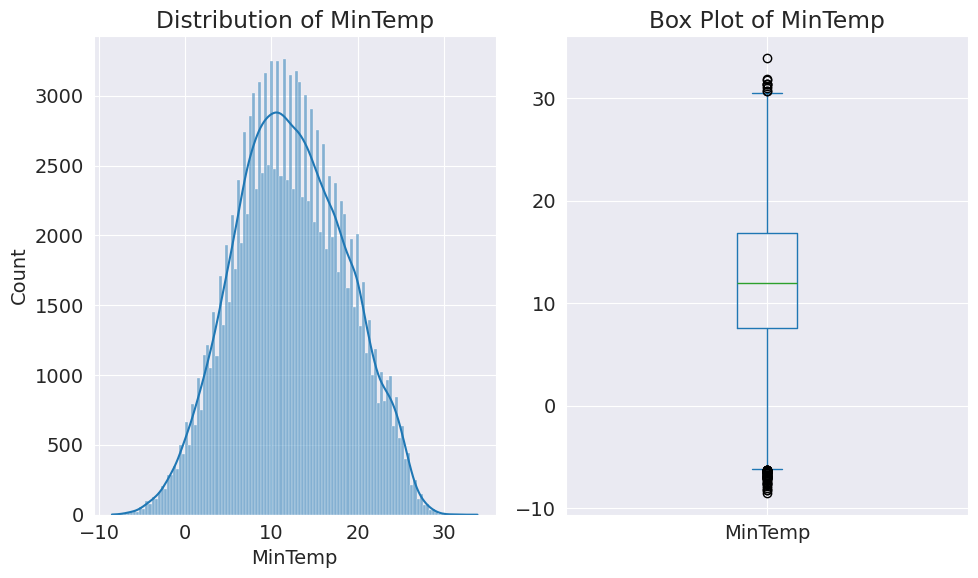

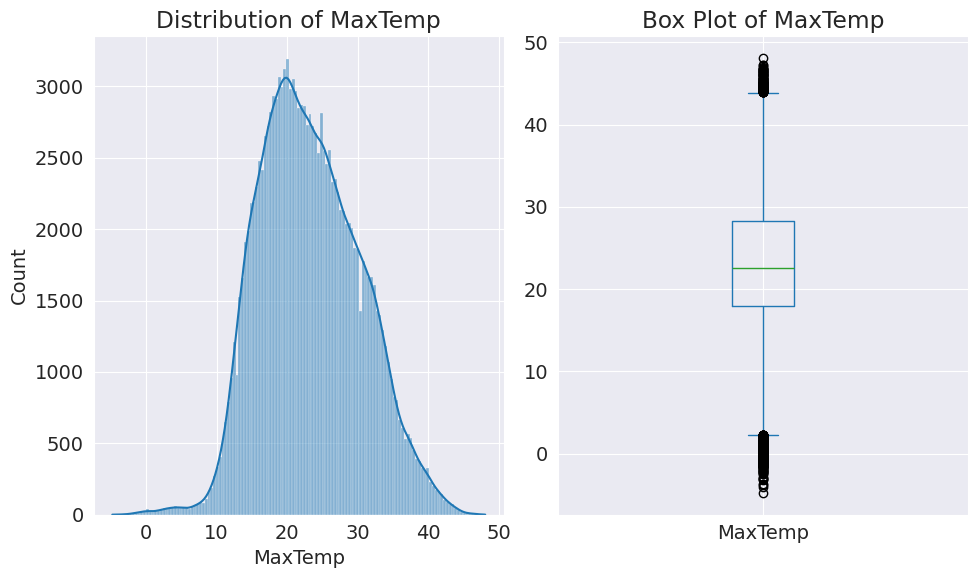

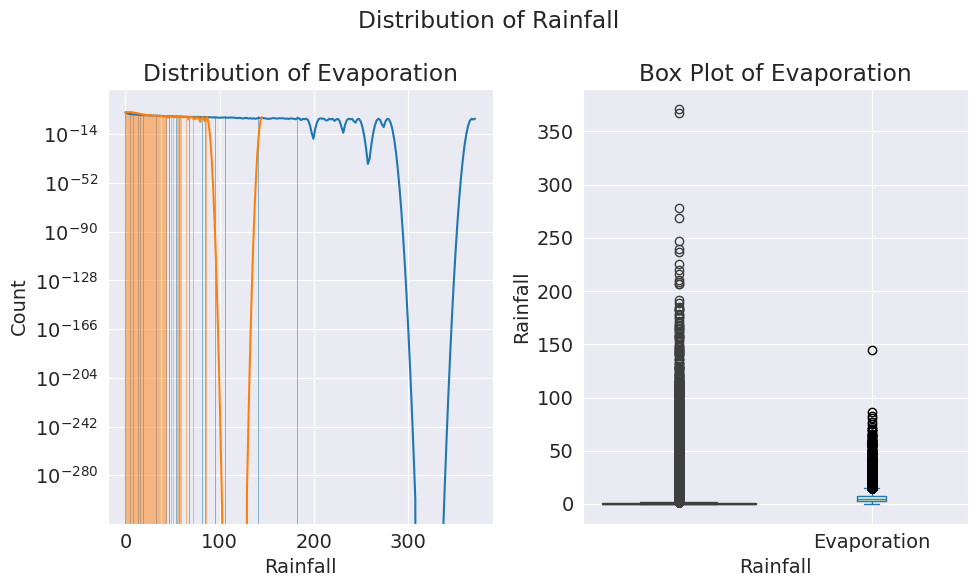

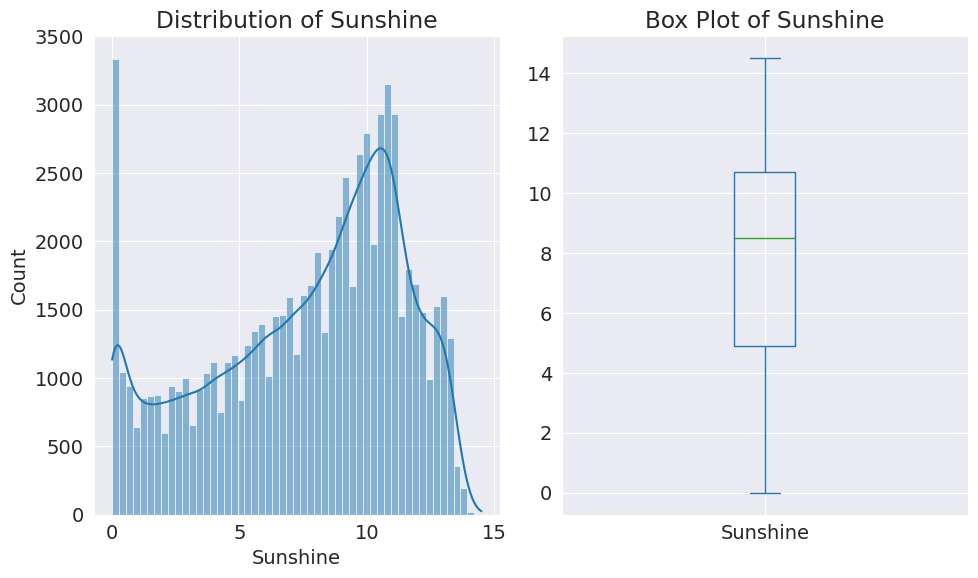

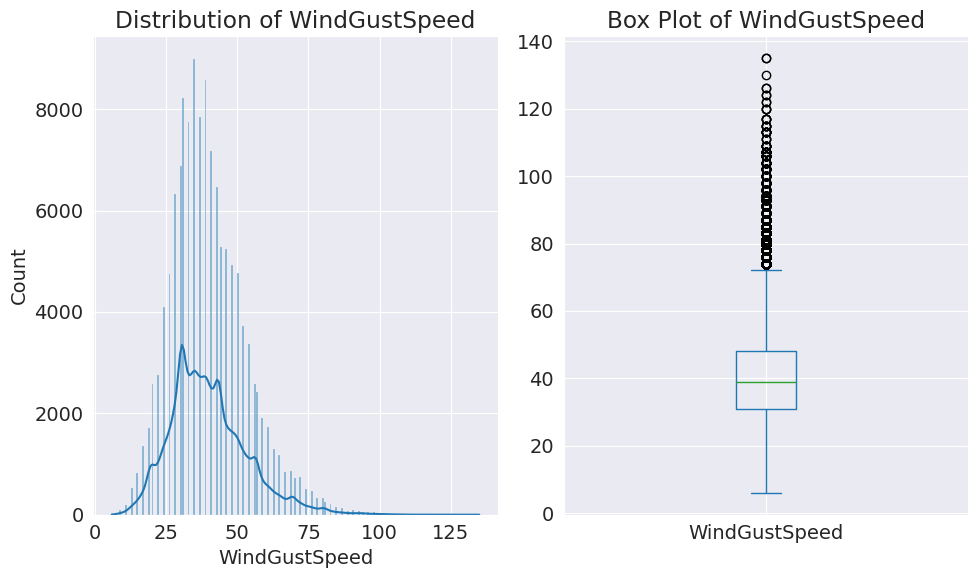

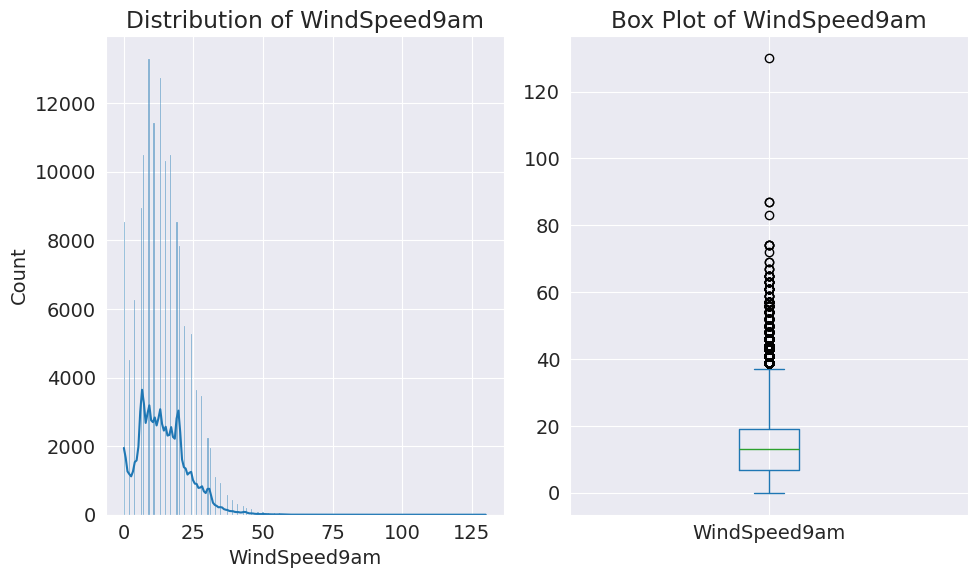

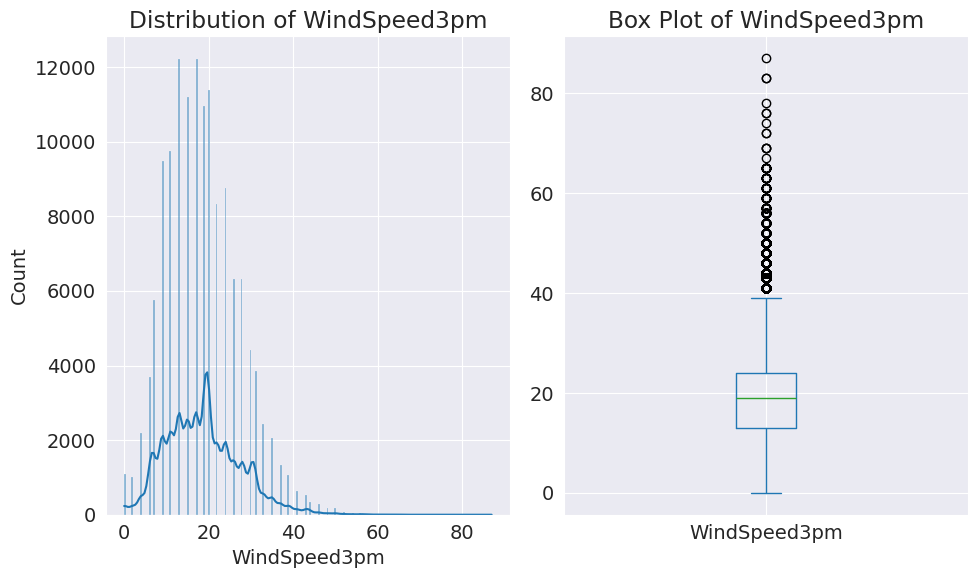

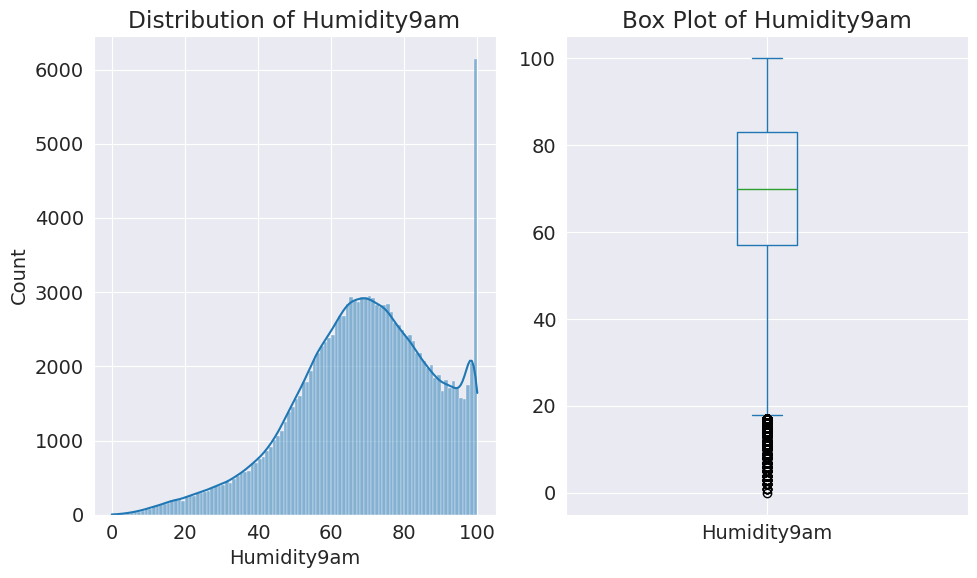

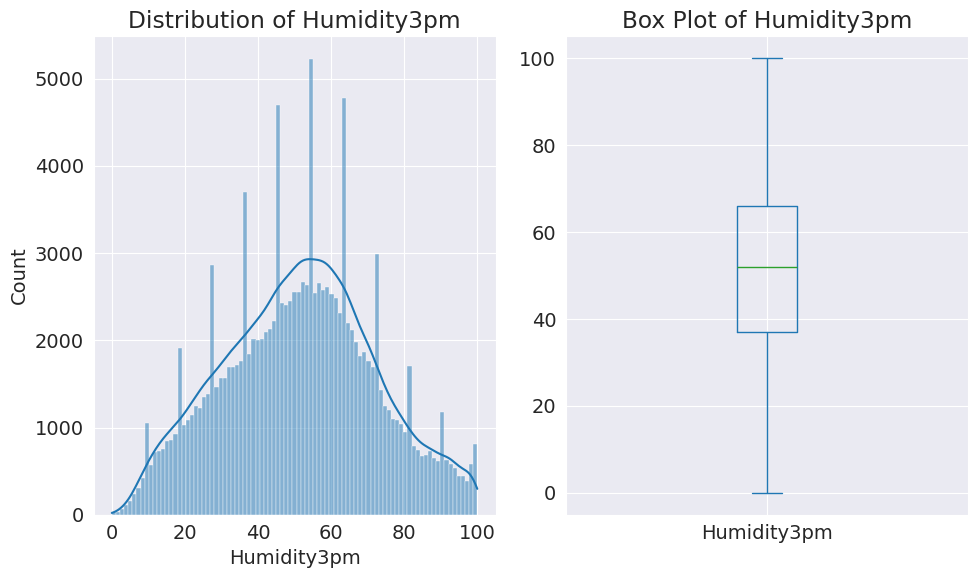

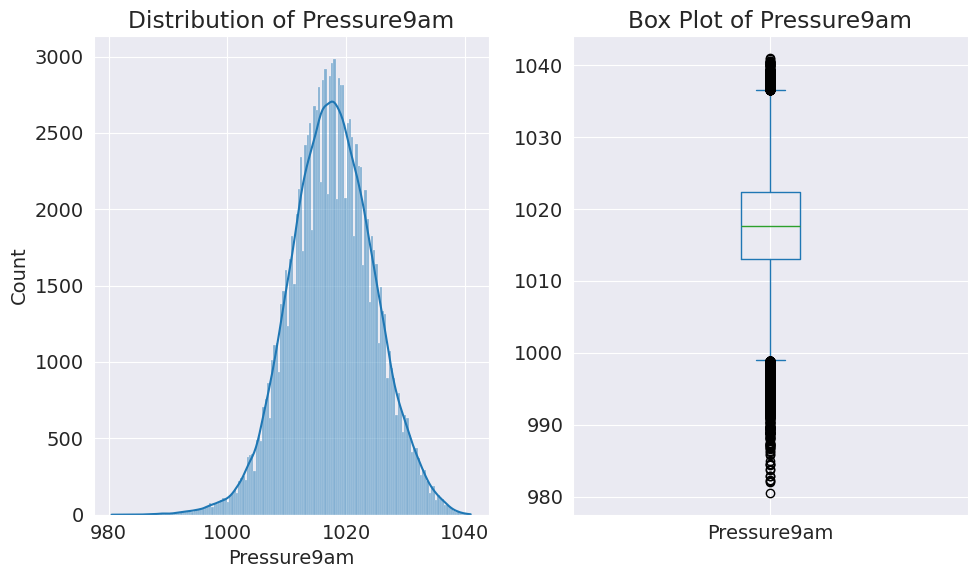

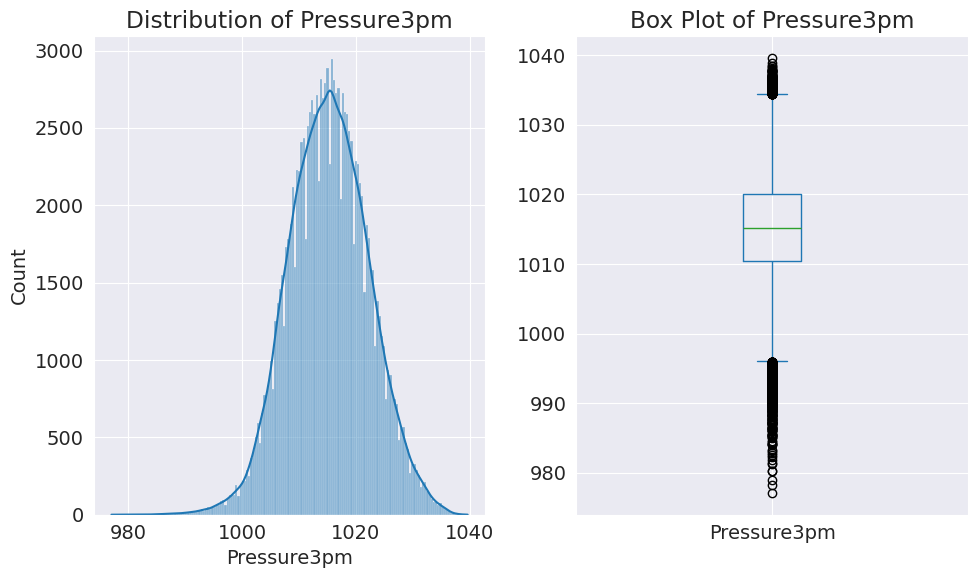

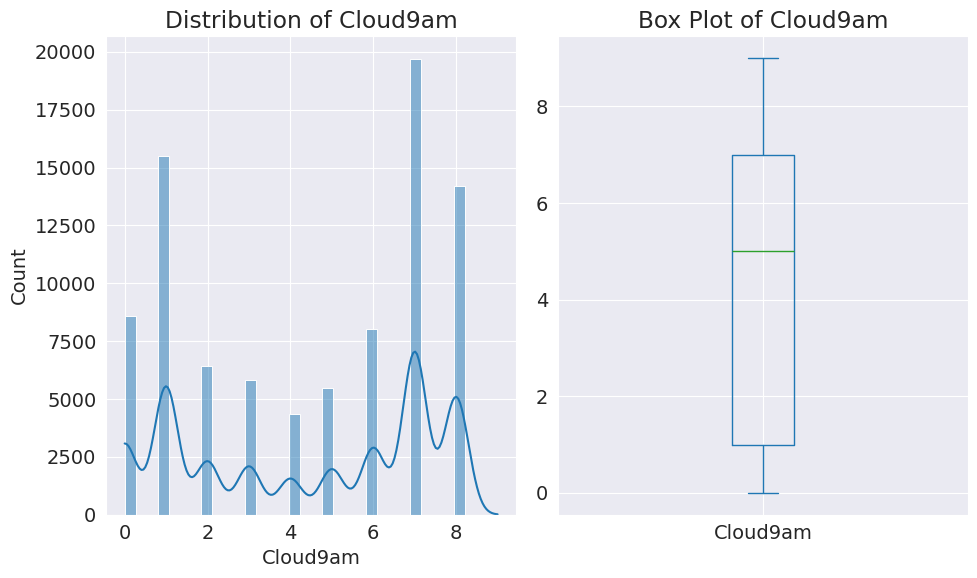

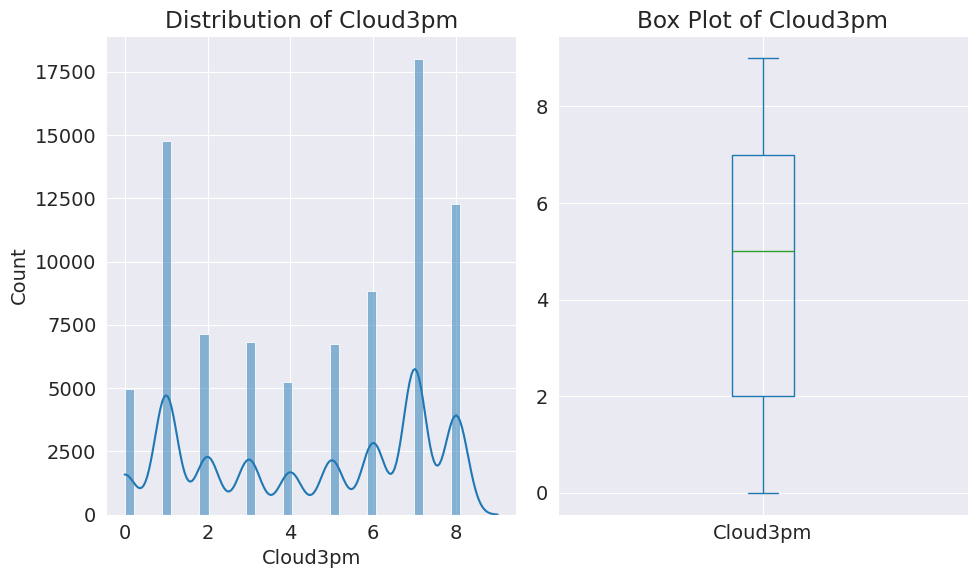

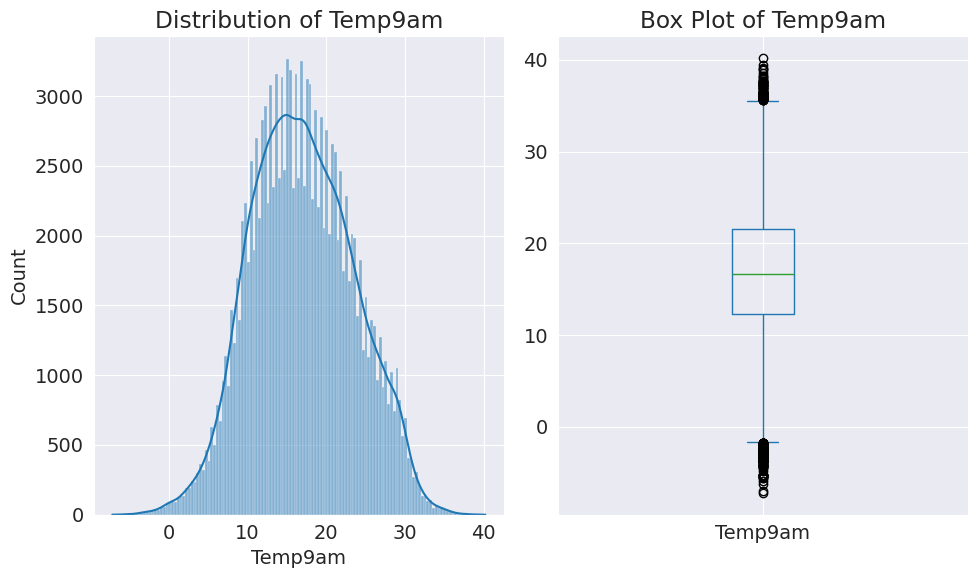

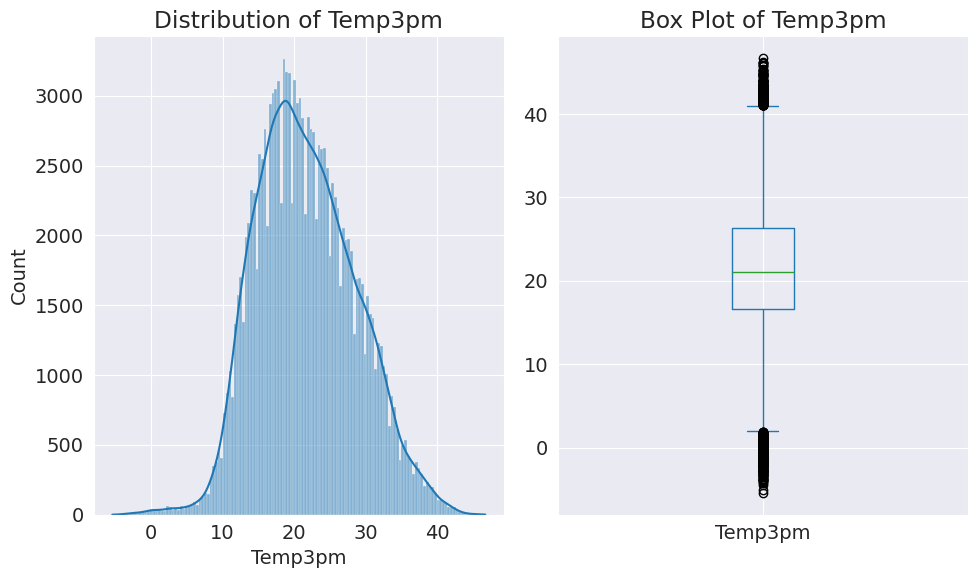

In [18]:
for col in numerical_cols:
  if col == "Rainfall":
    fig,ax=plt.subplots(1,2)
    fig.suptitle(f"Distribution of {col}")
    sns.histplot(raw_df[col],kde=True,ax=ax[0])
    ax[0].set_title("Distribution")
    ax[0].set_xlabel(col)
    ax[0].set_ylabel("Count")
    #ax[0].set_ylim(0,2000)
    ax[0].set_yscale("log")
    sns.boxplot(raw_df[col],ax=ax[1])
    ax[1].set_title("Box Plot")
    ax[1].set_xlabel(col)
  else :
    plt.subplot(1,2,1)
    sns.histplot(raw_df[col],kde=True)
    plt.title(f"Distribution of {col}")

    plt.subplot(1,2,2)
    raw_df[col].plot.box()
    plt.title(f"Box Plot of {col}")
    plt.subplots_adjust(wspace=0.5)
    plt.tight_layout(w_pad=1)
    plt.show()

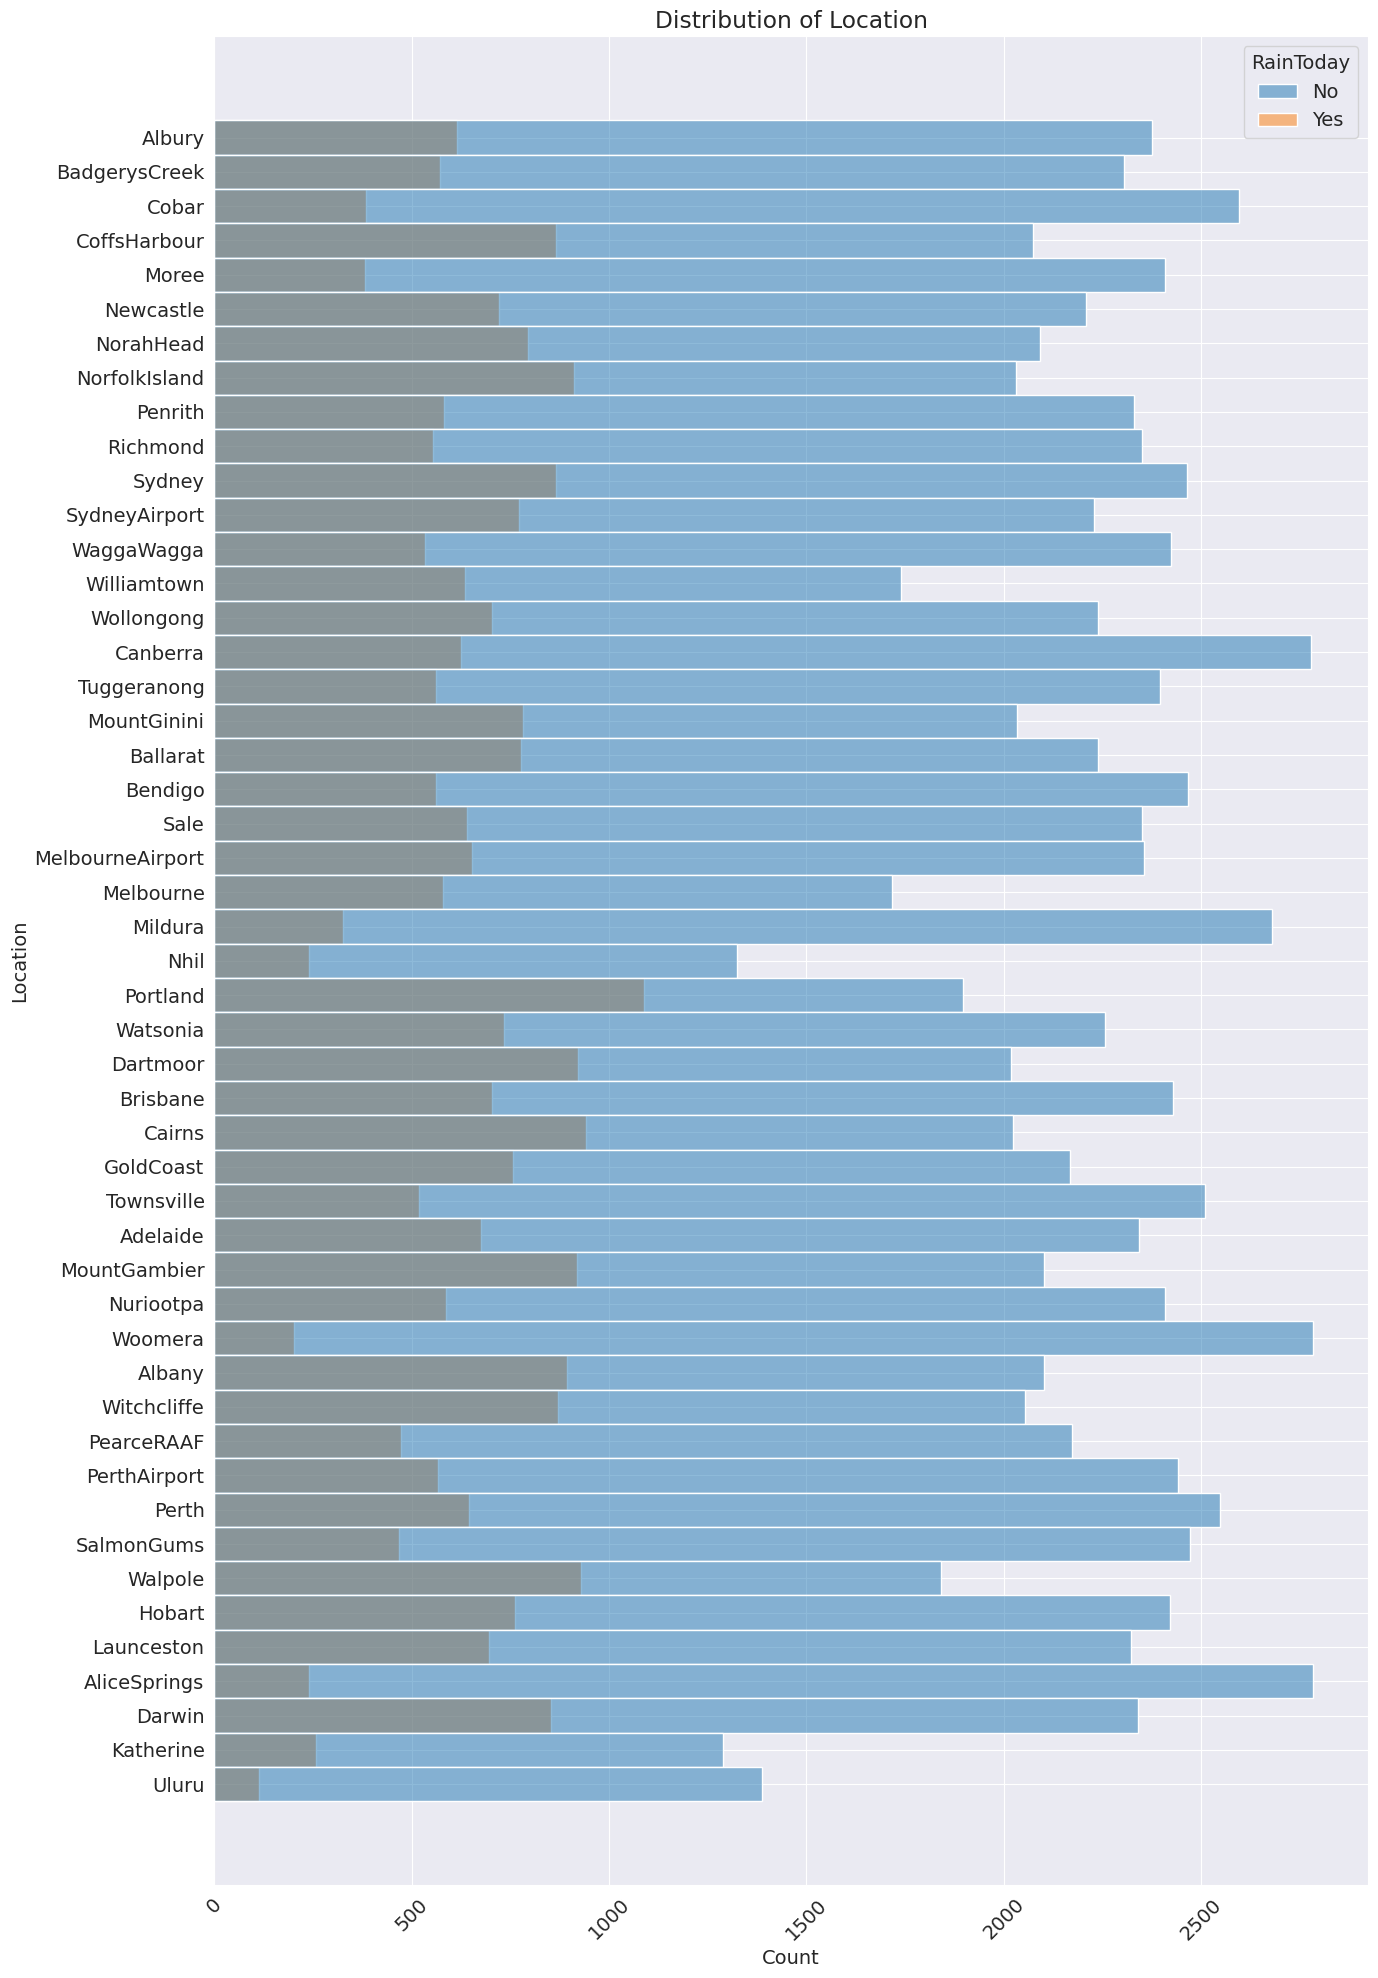

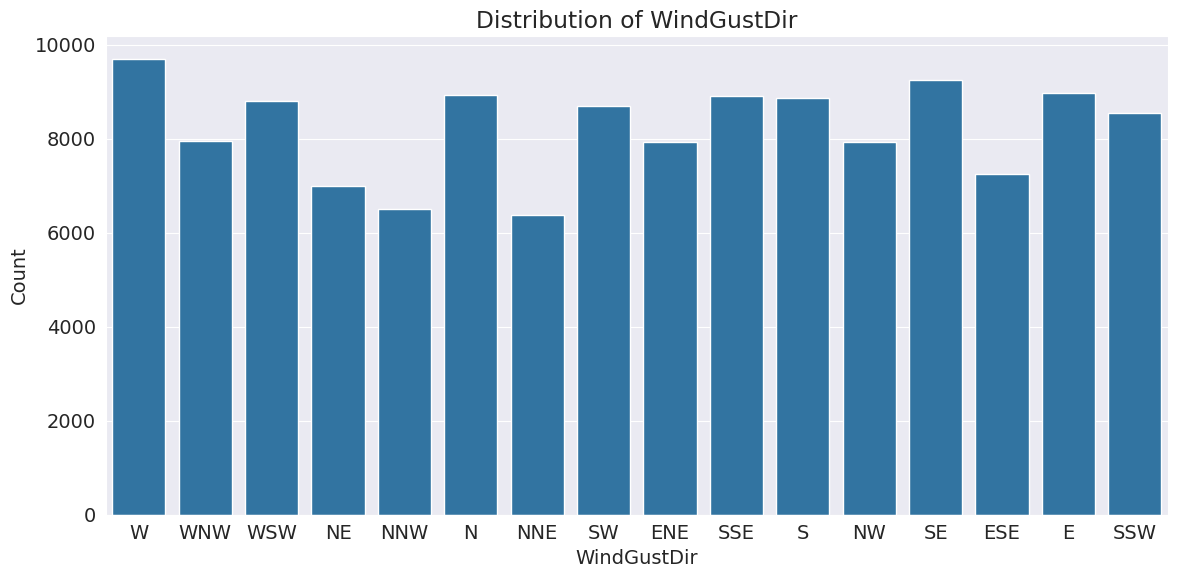

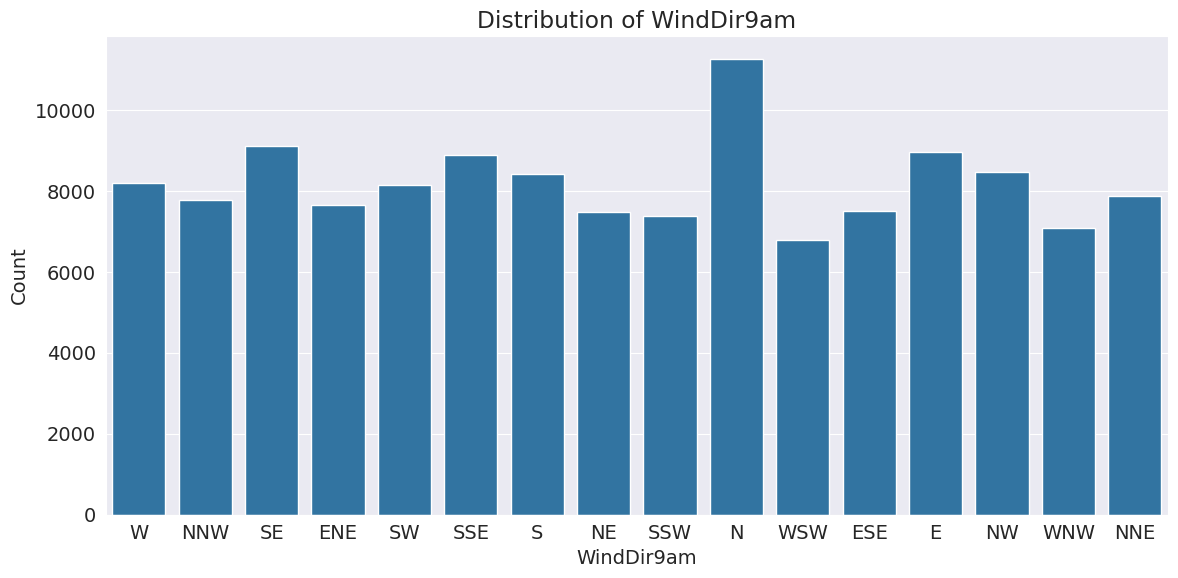

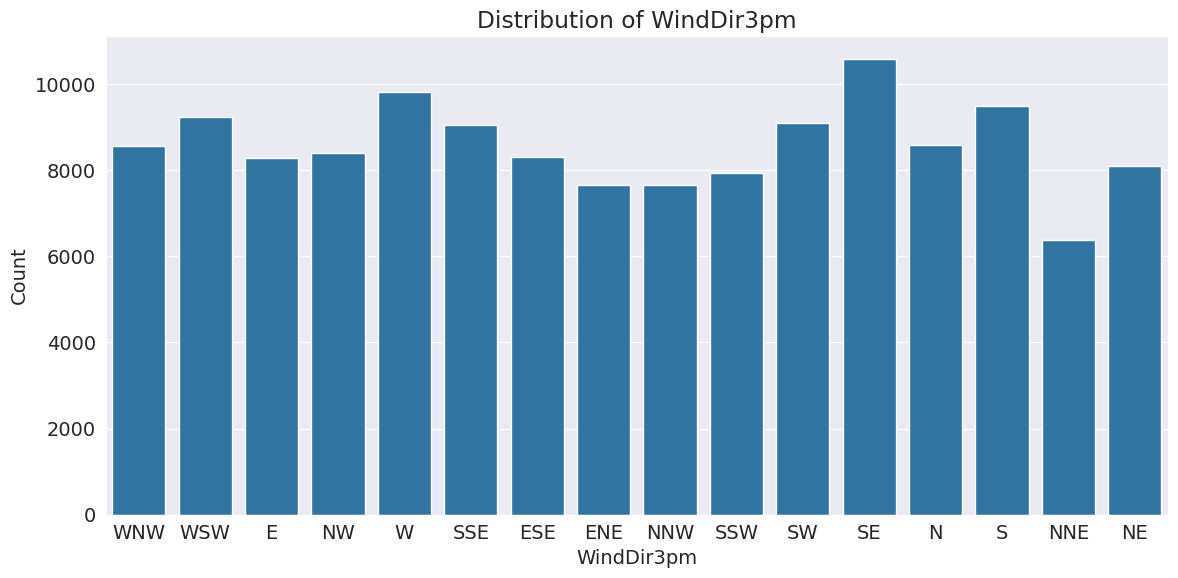

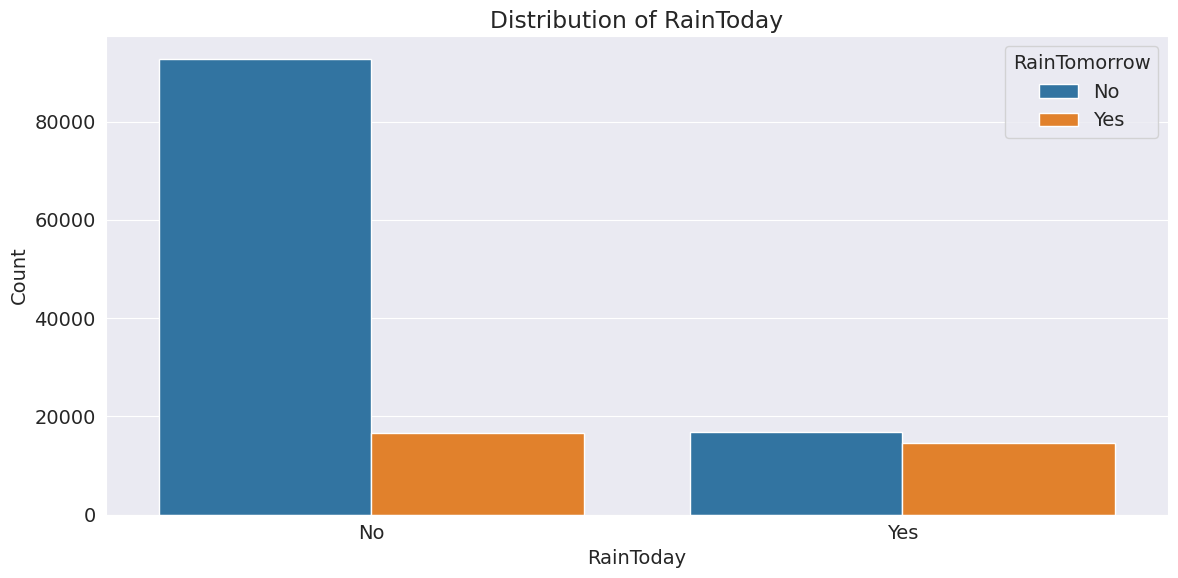

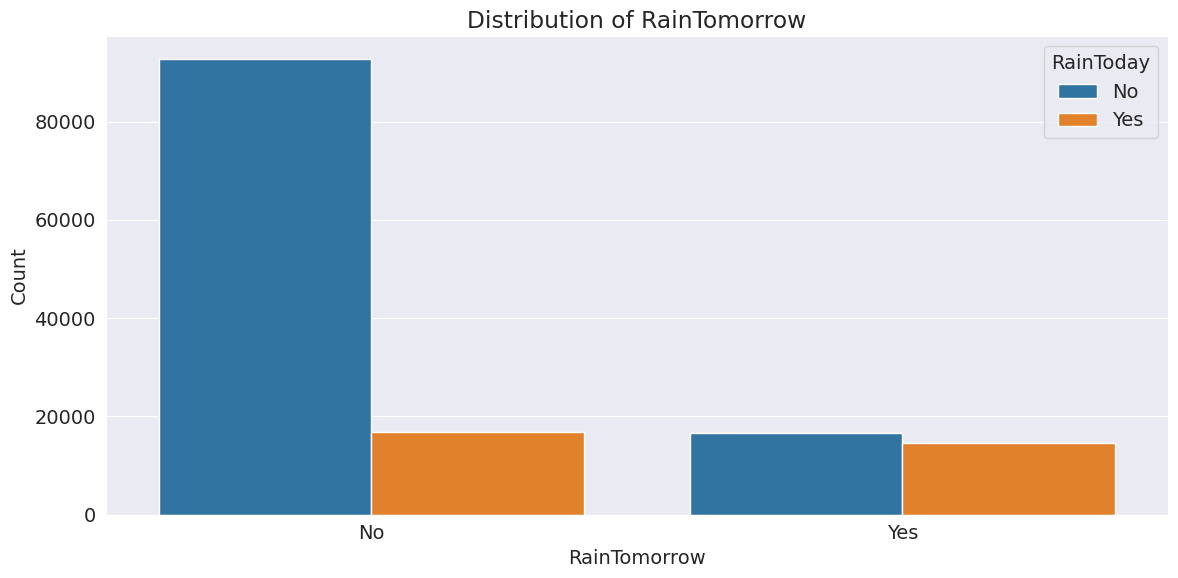

In [19]:
categorical_cols=raw_df.select_dtypes(include=object)
#categorical_cols.drop(columns=["Date","WindDir3pm","WindDir9am"], inplace= True)
for col in  categorical_cols:
  if col == "Date" :
    continue
  if col == "Location":
    plt.figure(figsize=(14, 20)) # Make it taller so cities aren't squashed
    plt.title(f"Distribution of {col}")

    # Change x=col to y=col here
    sns.histplot(
        data=raw_df, y=col,
        hue="RainToday",
        #order=raw_df[col].value_counts().index,
        )

    plt.xlabel("Count") # Label swaps: Count is now on the bottom
    plt.ylabel("Location")
    # You can remove plt.xticks(rotation=90) because text is now horizontal!
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
  elif col == "RainToday":
    plt.figure(figsize=(12, 6)) # Good to add this so graphs don't overlap
    plt.title(f"Distribution of {col}")
    sns.countplot(data=raw_df, x=col,hue="RainTomorrow")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()
  elif col == "RainTomorrow":
    plt.figure(figsize=(12, 6)) # Good to add this so graphs don't overlap
    plt.title(f"Distribution of {col}")
    sns.countplot(data=raw_df, x=col,hue="RainToday")
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()
  else:
    plt.figure(figsize=(12, 6)) # Good to add this so graphs don't overlap
    plt.title(f"Distribution of {col}")
    sns.countplot(data=raw_df, x=col)
    plt.ylabel("Count")
    plt.tight_layout()
    plt.show()



In [20]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 140787 entries, 0 to 145458
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           140787 non-null  object 
 1   Location       140787 non-null  object 
 2   MinTemp        140319 non-null  float64
 3   MaxTemp        140480 non-null  float64
 4   Rainfall       140787 non-null  float64
 5   Evaporation    81093 non-null   float64
 6   Sunshine       73982 non-null   float64
 7   WindGustDir    131624 non-null  object 
 8   WindGustSpeed  131682 non-null  float64
 9   WindDir9am     131127 non-null  object 
 10  WindDir3pm     137117 non-null  object 
 11  WindSpeed9am   139732 non-null  float64
 12  WindSpeed3pm   138256 non-null  float64
 13  Humidity9am    139270 non-null  float64
 14  Humidity3pm    137286 non-null  float64
 15  Pressure9am    127044 non-null  float64
 16  Pressure3pm    127018 non-null  float64
 17  Cloud9am       88162 non-null   fl

<Axes: xlabel='Evaporation', ylabel='Evaporation'>

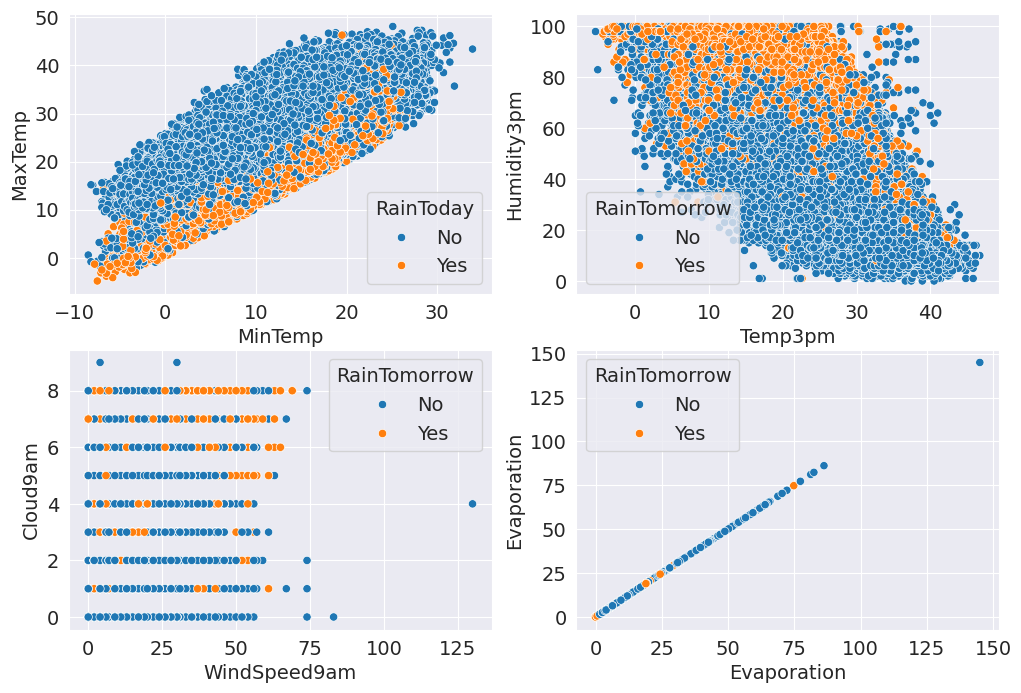

In [21]:
plt.figure(figsize=(12,8))
plt.subplot(2,2,1)
sns.scatterplot(data=raw_df,x="MinTemp",y="MaxTemp",hue="RainToday")
plt.subplot(2,2,2)
sns.scatterplot(data=raw_df,x="Temp3pm",y="Humidity3pm",hue="RainTomorrow")
plt.subplot(2,2,3)
sns.scatterplot(data=raw_df,x="WindSpeed9am",y="Cloud9am",hue="RainTomorrow")
plt.subplot(2,2,4)
sns.scatterplot(data=raw_df,x="Evaporation",y="Evaporation",hue="RainTomorrow")




In [22]:
# if u want to work with large amount of data like 1 millon amount of data
# we can create a  sample from the whole dataframe like  100k from 1m
use_sample= False
sample_fraction=0.1
if use_sample:
  raw_df=raw_df.sample(frac=sample_fraction).copy
#  this gonna save alot of time

# Trainnig , Validation and Test Sets

trainnig set = the class example
validation set= textbook exercise
test set= school exam
we can use 60% ,20%,20% for the 3 respectively
buh if the test set is provided we can use 75% and 25%

In [23]:
from sklearn.model_selection import train_test_split

In [24]:
#train_val,test_df= train_test_split(raw_df,test_size=0.2,random_state=42)
#train_df,val_df= train_test_split(train_val,test_size=0.25,random_state=42)


In [25]:
"""print("train_df.shape:",train_df.shape)
print("val_df.shape:", val_df.shape)''
print("test_df.shape:",test_df.shape)
"""

'print("train_df.shape:",train_df.shape)\nprint("val_df.shape:", val_df.shape)\'\'\nprint("test_df.shape:",test_df.shape)\n'

In [26]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 140787 entries, 0 to 145458
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           140787 non-null  object 
 1   Location       140787 non-null  object 
 2   MinTemp        140319 non-null  float64
 3   MaxTemp        140480 non-null  float64
 4   Rainfall       140787 non-null  float64
 5   Evaporation    81093 non-null   float64
 6   Sunshine       73982 non-null   float64
 7   WindGustDir    131624 non-null  object 
 8   WindGustSpeed  131682 non-null  float64
 9   WindDir9am     131127 non-null  object 
 10  WindDir3pm     137117 non-null  object 
 11  WindSpeed9am   139732 non-null  float64
 12  WindSpeed3pm   138256 non-null  float64
 13  Humidity9am    139270 non-null  float64
 14  Humidity3pm    137286 non-null  float64
 15  Pressure9am    127044 non-null  float64
 16  Pressure3pm    127018 non-null  float64
 17  Cloud9am       88162 non-null   fl

is better to use the date when dealing with time series analysis than the train_split_test

<Axes: title={'center': 'No of Row per Year'}, xlabel='Date', ylabel='count'>

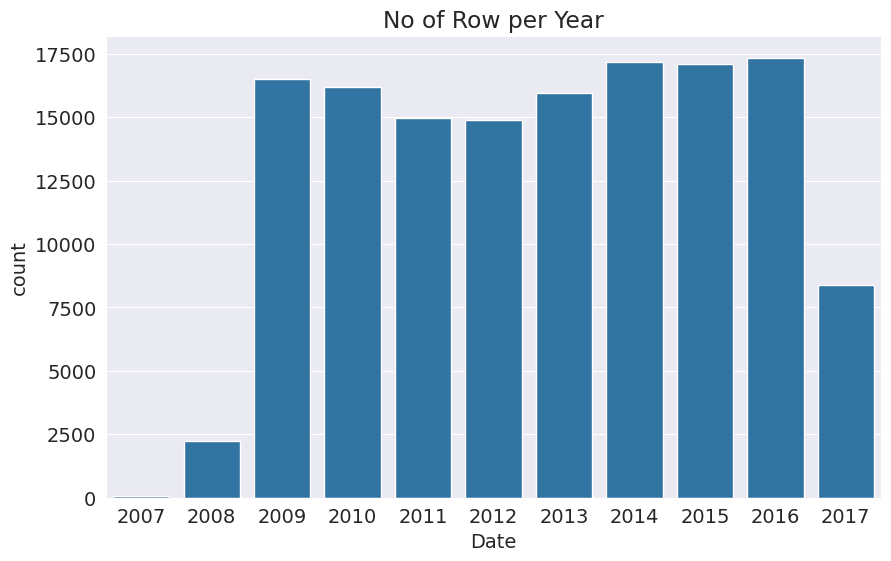

In [27]:
plt.title("No of Row per Year")
sns.countplot(x=pd.to_datetime(raw_df.Date).dt.year)

In [28]:
year= pd.to_datetime(raw_df.Date).dt.year
train_df=raw_df[year<2015]
val_df=raw_df[year==2015]
test_df= raw_df[year>2015]


In [29]:
print("train_df.shape:",train_df.shape)
print("val_df.shape:", val_df.shape)
print("test_df.shape:",test_df.shape)

train_df.shape: (97988, 23)
val_df.shape: (17089, 23)
test_df.shape: (25710, 23)


In [30]:
train_df.head()

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [31]:
# u av to remove the the target and cols that does not really matters
input_cols=list(train_df.columns)[1:-1]

input_cols


['Location',
 'MinTemp',
 'MaxTemp',
 'Rainfall',
 'Evaporation',
 'Sunshine',
 'WindGustDir',
 'WindGustSpeed',
 'WindDir9am',
 'WindDir3pm',
 'WindSpeed9am',
 'WindSpeed3pm',
 'Humidity9am',
 'Humidity3pm',
 'Pressure9am',
 'Pressure3pm',
 'Cloud9am',
 'Cloud3pm',
 'Temp9am',
 'Temp3pm',
 'RainToday']

In [32]:
target_col="RainTomorrow"

In [33]:
train_input=train_df[input_cols].copy()
train_target=train_df[target_col].copy()

In [34]:
val_input=val_df[input_cols].copy()
val_target=val_df[target_col].copy()

In [35]:
test_input=test_df[input_cols].copy()
test_target=test_df[target_col].copy()

In [36]:
train_input.head()

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday
0,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,...,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No
1,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,...,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No
2,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,...,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No
3,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,...,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No
4,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,...,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No


In [37]:
train_target.shape

(97988,)

In [38]:
import numpy as np

In [39]:
numerical_cols=train_input.select_dtypes(include=np.number).columns.tolist()

In [40]:
numerical_cols

['MinTemp',
 'MaxTemp',
 'Rainfall',
 'Evaporation',
 'Sunshine',
 'WindGustSpeed',
 'WindSpeed9am',
 'WindSpeed3pm',
 'Humidity9am',
 'Humidity3pm',
 'Pressure9am',
 'Pressure3pm',
 'Cloud9am',
 'Cloud3pm',
 'Temp9am',
 'Temp3pm']

In [41]:
categorical_cols=train_input.select_dtypes(include=object).columns.tolist()

In [42]:
train_input[numerical_cols].describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,97674.000000,97801.000000,97988.000000,61657.000000,57942.000000,91160.000000,97114.000000,96919.000000,96936.000000,96872.000000,88876.000000,88857.000000,63000.000000,61966.000000,97414.000000,97392.000000
mean,12.007831,23.022202,2.372935,5.289991,7.609004,40.215873,14.092263,18.764608,68.628745,51.469547,1017.513734,1015.132352,4.302952,4.410677,16.835126,21.540138
std,6.347175,6.984397,8.518819,3.952010,3.788813,13.697967,8.984203,8.872398,19.003097,20.756113,7.072510,6.997072,2.866634,2.693370,6.404586,6.831612
min,-8.500000,-4.100000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,979.000000,0.000000,0.000000,-5.900000,-5.100000
25%,7.500000,17.900000,0.000000,2.600000,4.800000,31.000000,7.000000,13.000000,57.000000,37.000000,1012.800000,1010.400000,1.000000,2.000000,12.200000,16.600000
50%,11.800000,22.400000,0.000000,4.600000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.500000,1015.100000,5.000000,5.000000,16.600000,20.900000
75%,16.600000,27.900000,0.800000,7.200000,10.600000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.300000,1019.900000,7.000000,7.000000,21.400000,26.200000
max,33.900000,48.100000,371.000000,82.400000,14.300000,135.000000,87.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.100000


In [43]:
train_input[categorical_cols].describe()

,Location,WindGustDir,WindDir9am,WindDir3pm,RainToday
count,97988,91120,90969,96036,97988
unique,49,16,16,16,2
top,Canberra,W,N,SE,No
freq,2506,6672,8012,7603,76002


In [44]:
train_input[categorical_cols].nunique()

,0
Location,49
WindGustDir,16
WindDir9am,16
WindDir3pm,16
RainToday,2


# Filling The Outliers

In [45]:
from sklearn.impute import SimpleImputer

In [46]:
?SimpleImputer

In [47]:
imputer=SimpleImputer(strategy="mean")

In [48]:
raw_df[numerical_cols].isna().sum()

,0
MinTemp,468
MaxTemp,307
Rainfall,0
Evaporation,59694
Sunshine,66805
WindGustSpeed,9105
WindSpeed9am,1055
WindSpeed3pm,2531
Humidity9am,1517
Humidity3pm,3501


In [49]:
train_input[numerical_cols].isna().sum()

,0
MinTemp,314
MaxTemp,187
Rainfall,0
Evaporation,36331
Sunshine,40046
WindGustSpeed,6828
WindSpeed9am,874
WindSpeed3pm,1069
Humidity9am,1052
Humidity3pm,1116


In [50]:
imputer.fit(raw_df[numerical_cols])

SimpleImputer()

list(imputer.statistics_)

In [51]:
train_input[numerical_cols]=imputer.transform(train_input[numerical_cols])
val_input[numerical_cols]=imputer.transform(val_input[numerical_cols])
test_input[numerical_cols]=imputer.transform(test_input[numerical_cols])

In [52]:
train_input[numerical_cols].isna().sum()

,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
Sunshine,0
WindGustSpeed,0
WindSpeed9am,0
WindSpeed3pm,0
Humidity9am,0
Humidity3pm,0


In [53]:
raw_df[numerical_cols].describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,140319.000000,140480.00000,140787.000000,81093.000000,73982.000000,131682.000000,139732.000000,138256.000000,139270.000000,137286.000000,127044.000000,127018.000000,88162.000000,84693.000000,140131.000000,138163.000000
mean,12.184824,23.23512,2.349974,5.472516,7.630540,39.970520,13.990496,18.631141,68.826833,51.449288,1017.654577,1015.257963,4.431161,4.499250,16.987066,21.693183
std,6.403879,7.11450,8.465173,4.189132,3.781729,13.578201,8.886210,8.798096,19.063650,20.807310,7.104867,7.035411,2.886594,2.719752,6.496012,6.937784
min,-8.500000,-4.80000,0.000000,0.000000,0.000000,6.000000,0.000000,0.000000,0.000000,0.000000,980.500000,977.100000,0.000000,0.000000,-7.200000,-5.400000
25%,7.600000,17.90000,0.000000,2.600000,4.900000,31.000000,7.000000,13.000000,57.000000,37.000000,1013.000000,1010.400000,1.000000,2.000000,12.300000,16.600000
50%,12.000000,22.60000,0.000000,4.800000,8.500000,39.000000,13.000000,19.000000,70.000000,52.000000,1017.600000,1015.200000,5.000000,5.000000,16.700000,21.100000
75%,16.800000,28.30000,0.800000,7.400000,10.700000,48.000000,19.000000,24.000000,83.000000,66.000000,1022.400000,1020.000000,7.000000,7.000000,21.600000,26.400000
max,33.900000,48.10000,371.000000,145.000000,14.500000,135.000000,130.000000,87.000000,100.000000,100.000000,1041.000000,1039.600000,9.000000,9.000000,40.200000,46.700000


In [54]:
from sklearn.preprocessing import MinMaxScaler

In [55]:
?MinMaxScaler

In [56]:
scaler= MinMaxScaler().fit(raw_df[numerical_cols])

In [57]:
print("minimum:")
list(scaler.data_min_)

minimum:


[np.float64(-8.5),
 np.float64(-4.8),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(6.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(980.5),
 np.float64(977.1),
 np.float64(0.0),
 np.float64(0.0),
 np.float64(-7.2),
 np.float64(-5.4)]

In [58]:
print("maximum:")
list(scaler.data_max_)

maximum:


[np.float64(33.9),
 np.float64(48.1),
 np.float64(371.0),
 np.float64(145.0),
 np.float64(14.5),
 np.float64(135.0),
 np.float64(130.0),
 np.float64(87.0),
 np.float64(100.0),
 np.float64(100.0),
 np.float64(1041.0),
 np.float64(1039.6),
 np.float64(9.0),
 np.float64(9.0),
 np.float64(40.2),
 np.float64(46.7)]

In [59]:
print("Range: ")
list(scaler.data_range_)

Range: 


[np.float64(42.4),
 np.float64(52.9),
 np.float64(371.0),
 np.float64(145.0),
 np.float64(14.5),
 np.float64(129.0),
 np.float64(130.0),
 np.float64(87.0),
 np.float64(100.0),
 np.float64(100.0),
 np.float64(60.5),
 np.float64(62.499999999999886),
 np.float64(9.0),
 np.float64(9.0),
 np.float64(47.400000000000006),
 np.float64(52.1)]

In [60]:
train_input[numerical_cols]=scaler.transform(train_input[numerical_cols])
val_input[numerical_cols]=scaler.transform(val_input[numerical_cols])
test_input[numerical_cols]=scaler.transform(test_input[numerical_cols])

In [61]:
train_input[numerical_cols].describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000,97988.000000
mean,0.483689,0.525947,0.006396,0.036949,0.525366,0.265107,0.108395,0.215668,0.686309,0.514693,0.612014,0.608705,0.483192,0.493693,0.507089,0.517103
std,0.149458,0.131904,0.022962,0.021628,0.200931,0.102420,0.068800,0.101424,0.189008,0.206376,0.111335,0.106611,0.255486,0.238028,0.134722,0.130726
min,0.000000,0.013233,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.030400,0.000000,0.000000,0.027426,0.005758
25%,0.377358,0.429112,0.000000,0.026207,0.517241,0.193798,0.053846,0.149425,0.570000,0.370000,0.543802,0.540800,0.333333,0.333333,0.409283,0.422265
50%,0.478774,0.514178,0.000000,0.037741,0.526244,0.255814,0.100000,0.218391,0.690000,0.520000,0.614125,0.610527,0.492351,0.499917,0.502110,0.506718
75%,0.591981,0.618147,0.002156,0.038621,0.634483,0.310078,0.146154,0.275862,0.830000,0.650000,0.682645,0.675200,0.666667,0.666667,0.601266,0.604607
max,1.000000,1.000000,1.000000,0.568276,0.986207,1.000000,0.669231,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.988484


# Encoding Categorical Data

In [62]:
from sklearn.preprocessing import OneHotEncoder

In [63]:
encoder=OneHotEncoder(sparse_output=False,handle_unknown="ignore")

In [64]:
encoder.fit(raw_df[categorical_cols])

OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [65]:
encoder.categories_

[array(['Adelaide', 'Albany', 'Albury', 'AliceSprings', 'BadgerysCreek',
        'Ballarat', 'Bendigo', 'Brisbane', 'Cairns', 'Canberra', 'Cobar',
        'CoffsHarbour', 'Dartmoor', 'Darwin', 'GoldCoast', 'Hobart',
        'Katherine', 'Launceston', 'Melbourne', 'MelbourneAirport',
        'Mildura', 'Moree', 'MountGambier', 'MountGinini', 'Newcastle',
        'Nhil', 'NorahHead', 'NorfolkIsland', 'Nuriootpa', 'PearceRAAF',
        'Penrith', 'Perth', 'PerthAirport', 'Portland', 'Richmond', 'Sale',
        'SalmonGums', 'Sydney', 'SydneyAirport', 'Townsville',
        'Tuggeranong', 'Uluru', 'WaggaWagga', 'Walpole', 'Watsonia',
        'Williamtown', 'Witchcliffe', 'Wollongong', 'Woomera'],
       dtype=object),
 array(['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE',
        'SSW', 'SW', 'W', 'WNW', 'WSW', nan], dtype=object),
 array(['E', 'ENE', 'ESE', 'N', 'NE', 'NNE', 'NNW', 'NW', 'S', 'SE', 'SSE',
        'SSW', 'SW', 'W', 'WNW', 'WSW', nan], dtype=object),
 ar

In [66]:
#train_input[categorical_cols].nunique()
categorical_cols
train_input[categorical_cols].fillna("Unknown",inplace=True)
train_input[categorical_cols].isna().sum()

/tmp/ipykernel_2492/2437195850.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_input[categorical_cols].fillna("Unknown",inplace=True)


,0
Location,0
WindGustDir,6868
WindDir9am,7019
WindDir3pm,1952
RainToday,0


In [67]:
encoded_cols = list(encoder.get_feature_names_out(categorical_cols))
print(encoded_cols)

['Location_Adelaide', 'Location_Albany', 'Location_Albury', 'Location_AliceSprings', 'Location_BadgerysCreek', 'Location_Ballarat', 'Location_Bendigo', 'Location_Brisbane', 'Location_Cairns', 'Location_Canberra', 'Location_Cobar', 'Location_CoffsHarbour', 'Location_Dartmoor', 'Location_Darwin', 'Location_GoldCoast', 'Location_Hobart', 'Location_Katherine', 'Location_Launceston', 'Location_Melbourne', 'Location_MelbourneAirport', 'Location_Mildura', 'Location_Moree', 'Location_MountGambier', 'Location_MountGinini', 'Location_Newcastle', 'Location_Nhil', 'Location_NorahHead', 'Location_NorfolkIsland', 'Location_Nuriootpa', 'Location_PearceRAAF', 'Location_Penrith', 'Location_Perth', 'Location_PerthAirport', 'Location_Portland', 'Location_Richmond', 'Location_Sale', 'Location_SalmonGums', 'Location_Sydney', 'Location_SydneyAirport', 'Location_Townsville', 'Location_Tuggeranong', 'Location_Uluru', 'Location_WaggaWagga', 'Location_Walpole', 'Location_Watsonia', 'Location_Williamtown', 'Loca

In [68]:
# Create encoded dataframes by transforming categorical columns from the original split dataframes
train_input[encoded_cols] = encoder.transform(train_input[categorical_cols])
val_input[encoded_cols] = encoder.transform(val_input[categorical_cols])
test_input[encoded_cols]= encoder.transform(test_input[categorical_cols])


/tmp/ipykernel_2492/693417361.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_input[encoded_cols] = encoder.transform(train_input[categorical_cols])
/tmp/ipykernel_2492/693417361.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train_input[encoded_cols] = encoder.transform(train_input[categorical_cols])
/tmp/ipykernel_2492/693417361.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at o

In [69]:
train_input.head()

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,...,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes
0,Albury,0.516509,0.523629,0.001617,0.037741,0.526244,W,0.294574,W,WNW,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,Albury,0.375000,0.565217,0.000000,0.037741,0.526244,WNW,0.294574,NNW,WSW,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,Albury,0.504717,0.576560,0.000000,0.037741,0.526244,WSW,0.310078,W,WSW,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,Albury,0.417453,0.620038,0.000000,0.037741,0.526244,NE,0.139535,SE,E,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,Albury,0.613208,0.701323,0.002695,0.037741,0.526244,W,0.271318,ENE,NW,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [70]:
train_input[encoded_cols]

,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,...,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes
0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144548,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
144549,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
144550,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
144551,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [71]:
pd.set_option('display.max_columns', None)

In [72]:
train_input.isna().sum()

,0
Location,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
...,...
WindDir3pm_WNW,0
WindDir3pm_WSW,0
WindDir3pm_nan,0
RainToday_No,0


# The Logistic Model

In [73]:
print("train_input: ",train_input.shape)
print("train_target: ",train_target.shape)
print("val_input: ",val_input.shape)
print("val_target: ",val_target.shape)
print("test_input: ",test_input.shape)
print("test_target: ",test_target.shape)

train_input:  (97988, 123)
train_target:  (97988,)
val_input:  (17089, 123)
val_target:  (17089,)
test_input:  (25710, 123)
test_target:  (25710,)


In [74]:
train_input.to_parquet("train_inputs.parquet")
val_input.to_parquet("val_inputs.parquet")
test_input.to_parquet("test_inputs.parquet")

In [75]:
pd.DataFrame(train_target).to_parquet("train_targets.parquet")
pd.DataFrame(val_target).to_parquet("val_targets.parquet")
pd.DataFrame(test_target).to_parquet("test_targets.parquet")

In [76]:
train_input=pd.read_parquet("train_inputs.parquet")
val_input=pd.read_parquet("val_inputs.parquet")
test_input=pd.read_parquet("test_inputs.parquet")

train_target=pd.read_parquet("train_targets.parquet")[target_col]
val_target=pd.read_parquet("val_targets.parquet")[target_col]
test_target=pd.read_parquet("test_targets.parquet")[target_col]


# Training The logistic mode

In [77]:
from sklearn.linear_model import LogisticRegression
?LogisticRegression

In [78]:
model=LogisticRegression(solver="liblinear")

In [79]:
train_input.isna().sum()

,0
Location,0
MinTemp,0
MaxTemp,0
Rainfall,0
Evaporation,0
...,...
WindDir3pm_WNW,0
WindDir3pm_WSW,0
WindDir3pm_nan,0
RainToday_No,0


In [80]:
# Separate numerical and categorical columns from the reloaded dataframes
train_numerical_features = train_input[numerical_cols]
val_numerical_features = val_input[numerical_cols]
test_numerical_features = test_input[numerical_cols]

# Apply one-hot encoding to categorical columns
train_encoded_features = encoder.transform(train_input[categorical_cols])
val_encoded_features = encoder.transform(val_input[categorical_cols])
test_encoded_features = encoder.transform(test_input[categorical_cols])

# Convert encoded features to DataFrame with correct column names and index
train_encoded_df = pd.DataFrame(train_encoded_features, columns=encoded_cols, index=train_input.index)
val_encoded_df = pd.DataFrame(val_encoded_features, columns=encoded_cols, index=val_input.index)
test_encoded_df = pd.DataFrame(test_encoded_features, columns=encoded_cols, index=test_input.index)

# Concatenate numerical and encoded categorical features

train_model_input = pd.concat([train_numerical_features, train_encoded_df], axis=1)
val_model_input = pd.concat([val_numerical_features, val_encoded_df], axis=1)
test_model_input = pd.concat([test_numerical_features, test_encoded_df], axis=1)



In [81]:
"""# i can use this without going through all i went through at the top
train_model_input=train_input[numerical_cols+ encoded_cols]
val_model_input=val_input[numerical_cols+ encoded_cols]
test_model_input=test_input[numerical_cols+ encoded_cols]"""

'# i can use this without going through all i went through at the top\ntrain_model_input=train_input[numerical_cols+ encoded_cols]\nval_model_input=val_input[numerical_cols+ encoded_cols]\ntest_model_input=test_input[numerical_cols+ encoded_cols]'

In [82]:
# Fit the model
model.fit(train_model_input, train_target)

LogisticRegression(solver='liblinear')

In [83]:
print(len(numerical_cols+ encoded_cols))

118


In [84]:
print(model.coef_.tolist())
print(len(np.array(model.coef_)[0,0:]))

[[0.8941494819914398, -2.8835981637598285, 3.16705385571896, 0.8748813625212737, -1.6712299421013947, 6.767350229914935, -0.9348274497098934, -1.4305423144580125, 0.32169035571609356, 5.998310719348589, 5.479442680901137, -9.193081641325355, -0.1617248603539462, 1.2877526299030033, 0.47427919277414954, 2.0306485635715577, 0.6006296229747108, -0.5482290695469623, 0.47582713818585737, 0.005403329094420832, 0.3448876907966021, -0.3541939045192693, 0.17792147945281966, 0.4398188899108637, -0.01537127061274263, 0.027474693408753546, 0.25694232549913004, -0.0218819867279193, -0.044852542203540485, -0.4845267257789648, -0.13899063231311373, -0.5770420446571881, -0.7889757132822478, -0.25772682848771616, -0.33014715004120004, -0.5704349639635146, 0.08010303171771241, 0.010434612808275893, 0.06303065657435758, -0.9041914913596089, -0.44254300410647857, 0.0036144590326460013, -0.46233657140847095, -0.4666993679113447, -0.0706491168142918, 0.1899331278715225, 0.4487399252051554, 0.606893959113903

In [85]:
print(model.intercept_)

[-2.51736667]


In [86]:
weight_df=pd.DataFrame({
    "feature": numerical_cols+ encoded_cols+["intercept"],
    "weight":np.append(np.array(model.coef_)[0],model.intercept_)

})


<Axes: xlabel='weight', ylabel='feature'>

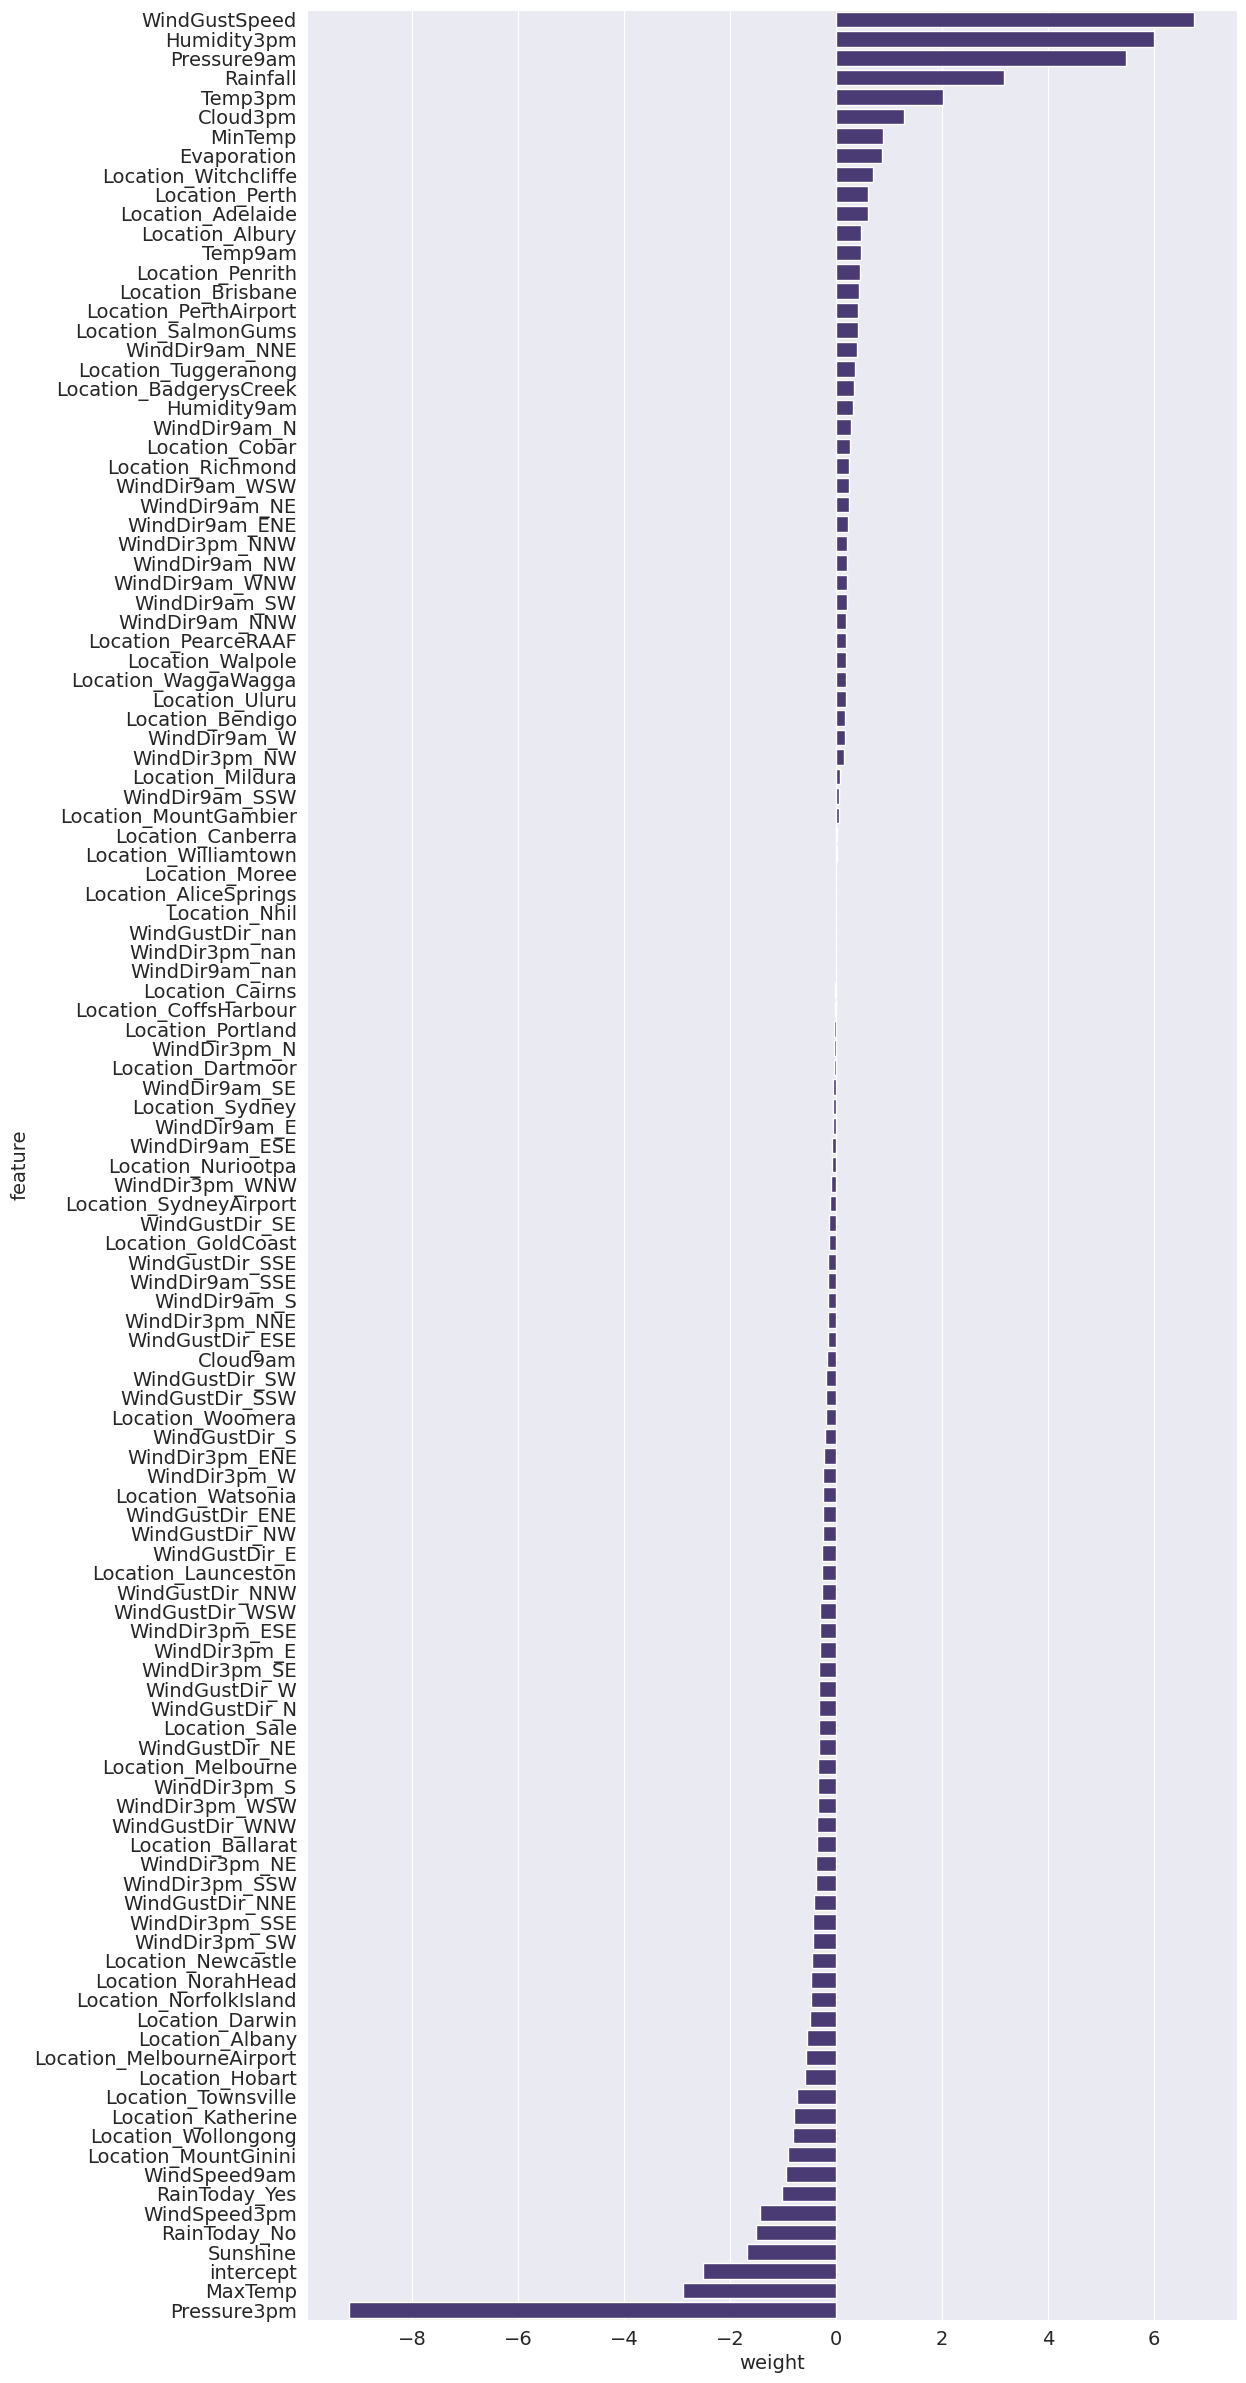

In [87]:
plt.figure(figsize=(12,30))
sns.set_palette("viridis")
sns.barplot(data=weight_df.sort_values("weight",ascending=False),x="weight",y="feature")

<Axes: xlabel='weight', ylabel='feature'>

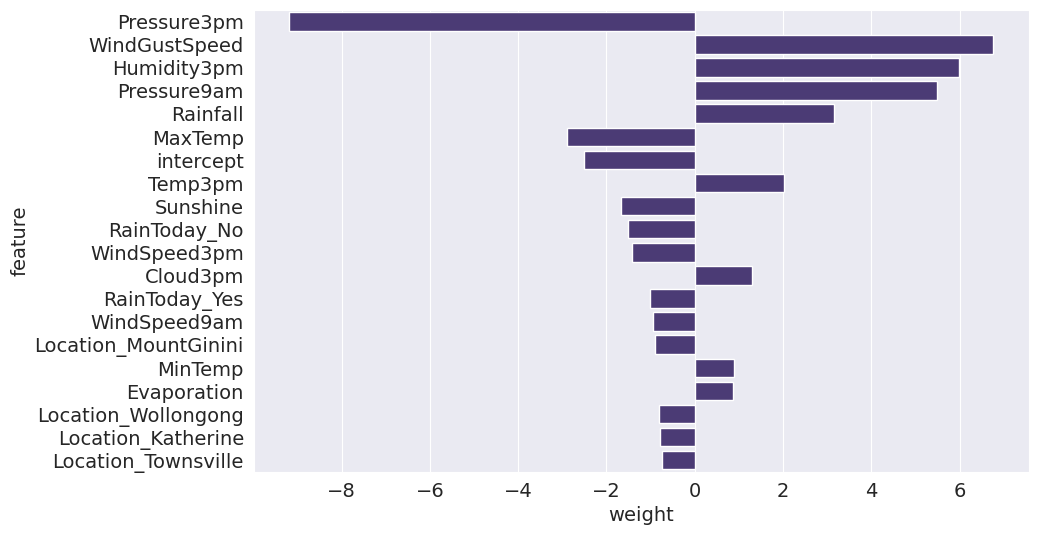

In [88]:
"""plt.figure(figsize=(12,8))
# Create a temporary column for absolute coefficients
weight_df['abs_coefficient'] = np.abs(weight_df["coefficient"])
# Use the new 'abs_coefficient' column for nlargest
sns.barplot(data=weight_df.nlargest(20,"abs_coefficient"),y="feature",x="coefficient")
# Remove the temporary column
weight_df.drop('abs_coefficient', axis=1, inplace=True) """
top_weight=np.abs(weight_df["weight"]).nlargest(20).index
sns.barplot(data= weight_df.loc[top_weight],x="weight",y="feature")
#


# Making Predictions and Evaluating Model

In [89]:
x_train=train_model_input
x_val=val_model_input
x_test=test_model_input

In [90]:
train_preds=model.predict(x_train)

In [91]:
train_preds

array(['No', 'No', 'No', ..., 'No', 'No', 'No'], dtype=object)

In [92]:
train_target

,RainTomorrow
0,No
1,No
2,No
3,No
4,No
...,...
144548,No
144549,No
144550,No
144551,No


In [93]:
model.classes_

array(['No', 'Yes'], dtype=object)

In [94]:
from sklearn.metrics import accuracy_score

In [95]:
accuracy_score(train_target,train_preds)

0.8519716700004082

In [96]:
from sklearn.metrics import confusion_matrix

In [97]:
confusion_matrix(train_target ,train_preds ,normalize="true")

array([[0.94622654, 0.05377346],
       [0.477475  , 0.522525  ]])

In [98]:
def predict_and_plot(inputs,targets,name):
  preds=model.predict(inputs)
  accuracy=accuracy_score(targets,preds)
  print(f"Accuracy : {accuracy * 100:.2f}%")

  cf=confusion_matrix(targets ,preds ,normalize="true")
  plt.figure()
  sns.heatmap(cf,annot=True)
  plt.xlabel("prediction")
  plt.ylabel("Target/Actual")
  plt.title(f"{name} Confusion Matrix")
  return(preds)

Accuracy : 85.20%


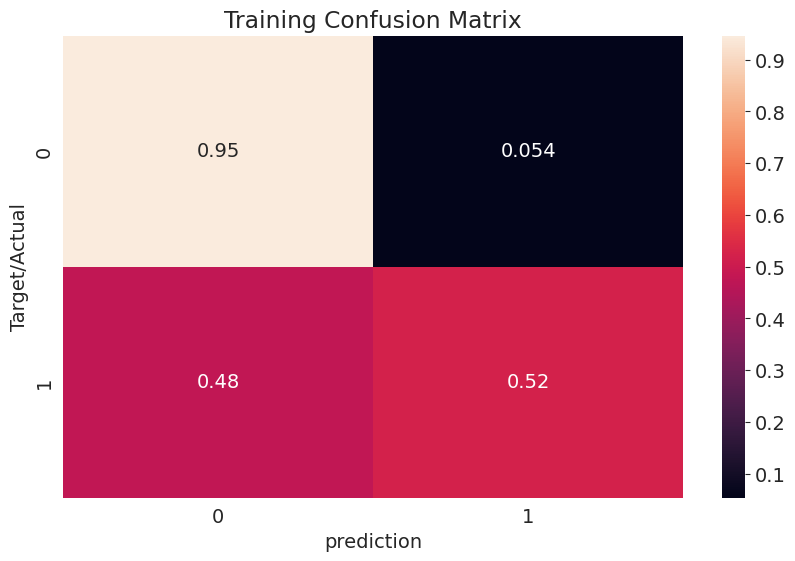

In [99]:
train_pre=predict_and_plot(x_train,train_target,"Training")

Accuracy : 85.41%


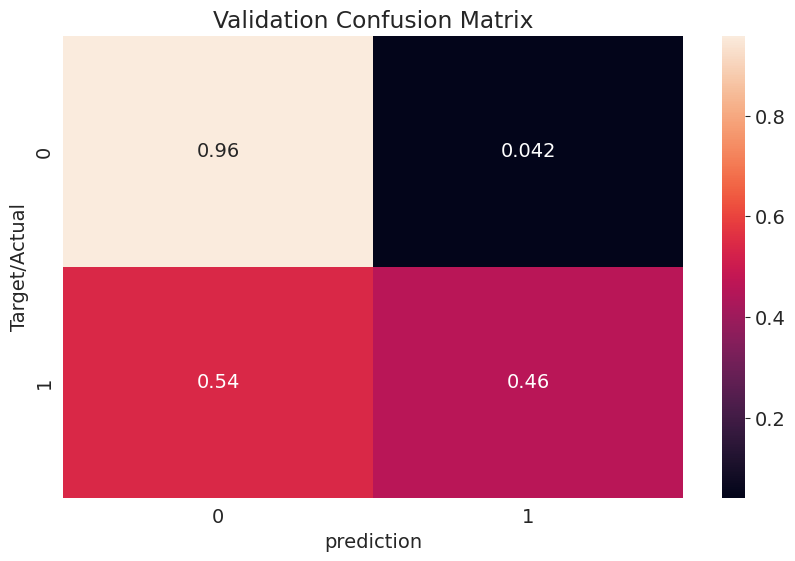

In [100]:
train_pre=predict_and_plot(x_val,val_target,"Validation")

Accuracy : 84.20%


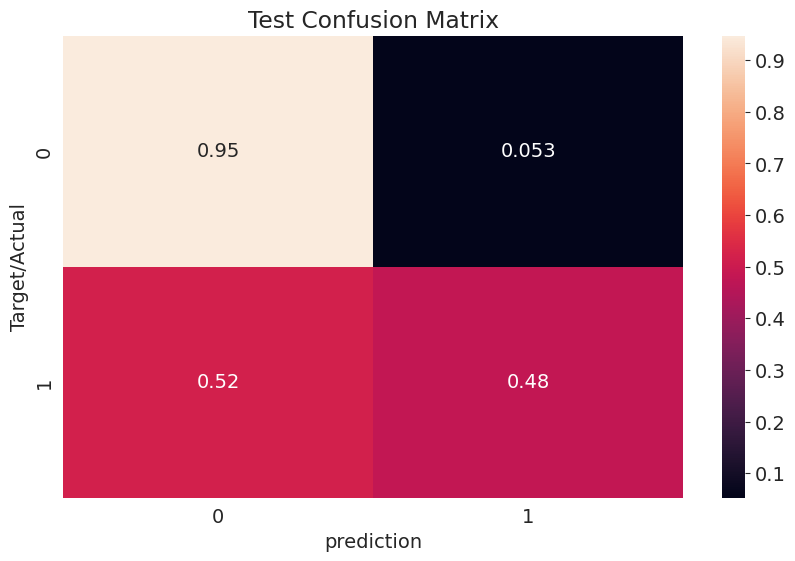

In [101]:
test_pre=predict_and_plot(x_test,test_target,"Test")

In [102]:
def random_guess(inputs):
  return np.random.choice(["No","Yes"],len(inputs))

In [103]:
def All_No(inputs):
  return np.full(len(inputs),"No")

In [104]:
random_guess(x_val)

array(['No', 'No', 'Yes', ..., 'No', 'Yes', 'Yes'], dtype='<U3')

In [105]:
All_No(x_val)

array(['No', 'No', 'No', ..., 'No', 'No', 'No'], dtype='<U2')

In [106]:
accuracy_score(test_target,random_guess(x_test))

0.4982497082847141

In [107]:
accuracy_score(test_target,All_No(x_test))

0.7734344612991054

In [108]:
sample_input = {
    'Location': 'Albury',
    'MinTemp': 13.4,
    'MaxTemp': 22.9,
    'Rainfall': 0.6,
    'Evaporation': 5.0,
    'Sunshine': 7.0,
    'WindGustDir': 'W',
    'WindGustSpeed': 44.0,
    'WindDir9am': 'W',
    'WindDir3pm': 'WNW',
    'WindSpeed9am': 20.0,
    'WindSpeed3pm': 24.0,
    'Humidity9am': 71.0,
    'Humidity3pm': 22.0,
    'Pressure9am': 1007.7,
    'Pressure3pm': 1007.1,
    'Cloud9am': 8.0,
    'Cloud3pm': 5.0,
    'Temp9am': 16.9,
    'Temp3pm': 21.8,
    'RainToday': 'No'
}

print(sample_input)

{'Location': 'Albury', 'MinTemp': 13.4, 'MaxTemp': 22.9, 'Rainfall': 0.6, 'Evaporation': 5.0, 'Sunshine': 7.0, 'WindGustDir': 'W', 'WindGustSpeed': 44.0, 'WindDir9am': 'W', 'WindDir3pm': 'WNW', 'WindSpeed9am': 20.0, 'WindSpeed3pm': 24.0, 'Humidity9am': 71.0, 'Humidity3pm': 22.0, 'Pressure9am': 1007.7, 'Pressure3pm': 1007.1, 'Cloud9am': 8.0, 'Cloud3pm': 5.0, 'Temp9am': 16.9, 'Temp3pm': 21.8, 'RainToday': 'No'}


In [109]:
sample_df=pd.DataFrame([sample_input])

In [110]:
sample_df

,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday
0,Albury,13.4,22.9,0.6,5.0,7.0,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,5.0,16.9,21.8,No


the input most go through all what the training set went through

In [111]:
sample_df[numerical_cols]=imputer.transform(sample_df[numerical_cols])
sample_df[numerical_cols]=scaler.transform(sample_df[numerical_cols])
sample_df[encoded_cols]=encoder.transform(sample_df[categorical_cols])

/tmp/ipykernel_2492/3815231539.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample_df[encoded_cols]=encoder.transform(sample_df[categorical_cols])
/tmp/ipykernel_2492/3815231539.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  sample_df[encoded_cols]=encoder.transform(sample_df[categorical_cols])
/tmp/ipykernel_2492/3815231539.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using

In [112]:
x_sample_input=sample_df[numerical_cols+encoded_cols]

In [113]:
x_sample_input

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,Location_Adelaide,Location_Albany,Location_Albury,Location_AliceSprings,Location_BadgerysCreek,Location_Ballarat,Location_Bendigo,Location_Brisbane,Location_Cairns,Location_Canberra,Location_Cobar,Location_CoffsHarbour,Location_Dartmoor,Location_Darwin,Location_GoldCoast,Location_Hobart,Location_Katherine,Location_Launceston,Location_Melbourne,Location_MelbourneAirport,Location_Mildura,Location_Moree,Location_MountGambier,Location_MountGinini,Location_Newcastle,Location_Nhil,Location_NorahHead,Location_NorfolkIsland,Location_Nuriootpa,Location_PearceRAAF,Location_Penrith,Location_Perth,Location_PerthAirport,Location_Portland,Location_Richmond,Location_Sale,Location_SalmonGums,Location_Sydney,Location_SydneyAirport,Location_Townsville,Location_Tuggeranong,Location_Uluru,Location_WaggaWagga,Location_Walpole,Location_Watsonia,Location_Williamtown,Location_Witchcliffe,Location_Wollongong,Location_Woomera,WindGustDir_E,WindGustDir_ENE,WindGustDir_ESE,WindGustDir_N,WindGustDir_NE,WindGustDir_NNE,WindGustDir_NNW,WindGustDir_NW,WindGustDir_S,WindGustDir_SE,WindGustDir_SSE,WindGustDir_SSW,WindGustDir_SW,WindGustDir_W,WindGustDir_WNW,WindGustDir_WSW,WindGustDir_nan,WindDir9am_E,WindDir9am_ENE,WindDir9am_ESE,WindDir9am_N,WindDir9am_NE,WindDir9am_NNE,WindDir9am_NNW,WindDir9am_NW,WindDir9am_S,WindDir9am_SE,WindDir9am_SSE,WindDir9am_SSW,WindDir9am_SW,WindDir9am_W,WindDir9am_WNW,WindDir9am_WSW,WindDir9am_nan,WindDir3pm_E,WindDir3pm_ENE,WindDir3pm_ESE,WindDir3pm_N,WindDir3pm_NE,WindDir3pm_NNE,WindDir3pm_NNW,WindDir3pm_NW,WindDir3pm_S,WindDir3pm_SE,WindDir3pm_SSE,WindDir3pm_SSW,WindDir3pm_SW,WindDir3pm_W,WindDir3pm_WNW,WindDir3pm_WSW,WindDir3pm_nan,RainToday_No,RainToday_Yes
0,0.516509,0.523629,0.001617,0.034483,0.482759,0.294574,0.153846,0.275862,0.71,0.22,0.449587,0.48,0.888889,0.555556,0.508439,0.522073,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [114]:
prediction=model.predict(x_sample_input)

In [115]:
prediction


array(['No'], dtype=object)

In [116]:
prob=model.predict_proba(x_sample_input)

In [117]:
prob

array([[0.93615194, 0.06384806]])

In [118]:
def predict_input(single_input):
  input_df=pd.DataFrame([single_input])
  input_df[numerical_cols]=imputer.transform(input_df[numerical_cols])
  input_df[numerical_cols]=scaler.transform(input_df[numerical_cols])
  input_df[categorical_cols]=input_df[categorical_cols].fillna("Unknown")
  input_df[encoded_cols]=encoder.transform(input_df[categorical_cols])
  x_input=input_df[numerical_cols+encoded_cols]
  pred=model.predict(x_input)[0]
  prob=model.predict_proba(x_input)[0][list(model.classes_).index(pred)]
  return {"prediction":pred,"probability":prob}

In [119]:
new_sample_input = {
    'Location': 'Sydney',
    'MinTemp': 15.0,
    'MaxTemp': 25.0,
    'Rainfall': 2.5,
    'Evaporation': 6.0,
    'Sunshine': 8.0,
    'WindGustDir': 'N',
    'WindGustSpeed': 35.0,
    'WindDir9am': 'NNE',
    'WindDir3pm': 'NNW',
    'WindSpeed9am': 15.0,
    'WindSpeed3pm': 20.0,
    'Humidity9am': 60.0,
    'Humidity3pm': 30.0,
    'Pressure9am': 1012.0,
    'Pressure3pm': 1010.0,
    'Cloud9am': 2.0,
    'Cloud3pm': 3.0,
    'Temp9am': 18.0,
    'Temp3pm': 24.0,
    'RainToday': 'Yes'
}

# Call the predict_input function with the new sample
new_prediction = predict_input(new_sample_input)


/tmp/ipykernel_2492/1602140260.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[encoded_cols]=encoder.transform(input_df[categorical_cols])
/tmp/ipykernel_2492/1602140260.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  input_df[encoded_cols]=encoder.transform(input_df[categorical_cols])
/tmp/ipykernel_2492/1602140260.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.

In [120]:
print(new_prediction)

{'prediction': 'No', 'probability': np.float64(0.9161842237282181)}


# Saving and Loading Trained Model

In [121]:
dictionary_rain= {
    "model":model,
    "imputer":imputer,
    "scaler":scaler,
    "encoder":encoder,
    "input_cols":input_cols,
    "target_col":target_col,
    "numerical_cols":numerical_cols,
    "categorical_cols":categorical_cols,
    "encoded_cols": encoded_cols
}